<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Clase 5, VGGT**



**VGGT** es un transformer ya entrenado que recibe varias fotos de una escena y, en una sola pasada, nos devuelve:

- la **posición de la cámara** en cada foto
- la **profundidad** de cada píxel
- los **puntos 3D** de la escena

---
## **0.- Preparación**

In [ ]:
# Descargamos el código de VGGT y las librerías que necesita
!git clone -q https://github.com/facebookresearch/vggt.git vggt_repo
!pip install -q einops safetensors huggingface_hub

# Descargamos un recorrido de KITTI (Karlsruhe, 2011) y lo descomprimimos
!wget -q https://s3.eu-central-1.amazonaws.com/avg-kitti/raw_data/2011_09_26_drive_0005/2011_09_26_drive_0005_sync.zip
!unzip -q -o 2011_09_26_drive_0005_sync.zip

In [ ]:
# Importamos las librerías que vamos a usar
import sys
sys.path.append("vggt_repo")

import numpy as np
import torch
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from glob import glob
from vggt.models.vggt import VGGT
from vggt.utils.load_fn import load_and_preprocess_images
from vggt.utils.pose_enc import pose_encoding_to_extri_intri

## **1.- Las fotos**

Usamos solo la cámara color izquierda del auto, toma 10 fotos por segundo

Cantidad de fotos: 154
Fotos que le daremos a VGGT: 16


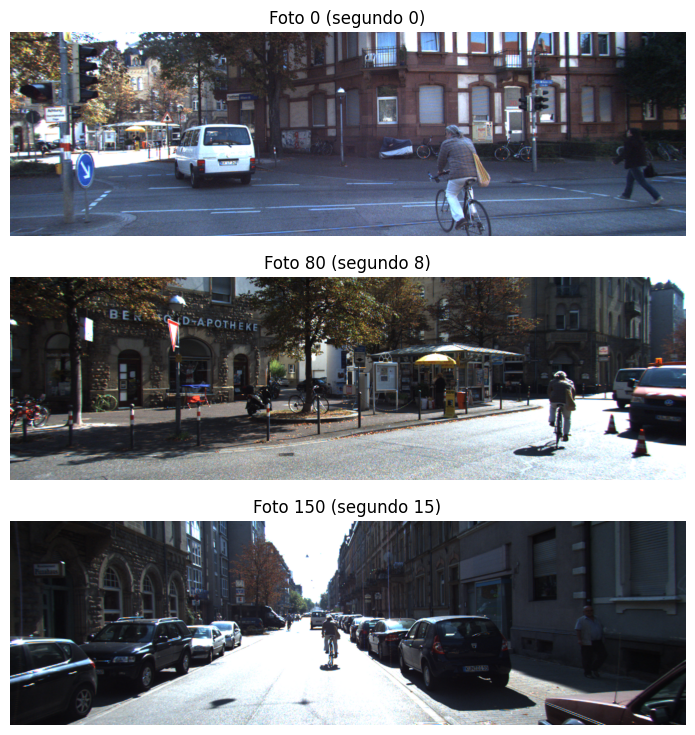

In [ ]:
# buscamos todas las fotos, ordenadas en el tiempo
CARPETA = "2011_09_26/2011_09_26_drive_0005_sync"
FOTOS = sorted(glob(CARPETA + "/image_02/data/*.png"))
print("Cantidad de fotos:", len(FOTOS))

# elegimos una foto de cada 10 (una por segundo, unas 16 en total)
CUADROS = list(range(0, len(FOTOS), 10))
print("Fotos que le daremos a VGGT:", len(CUADROS))

# miramos tres de ellas: al inicio, al medio y al final
fig, ax = plt.subplots(3, 1, figsize=(16, 9))
for a, k in zip(ax, [CUADROS[0], CUADROS[len(CUADROS) // 2], CUADROS[-1]]):
    a.imshow(plt.imread(FOTOS[k]))
    a.set_title(f"Foto {k} (segundo {k / 10:.0f})")
    a.axis("off")
plt.show()

## **2.- Pasamos las fotos por VGGT**

Le damos **todas las fotos juntas**: el modelo las mira a la vez y relaciona lo que aparece en cada una.

In [ ]:
# Usamos la GPU si hay una (en CPU también corre, pero mucho más lento)
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print("Usamos:", dispositivo)

# Descargamos el modelo preentrenado (unos 5 GB, tarda un poco la primera vez)
modelo = VGGT.from_pretrained("facebook/VGGT-1B").to(dispositivo).eval()

# VGGT achica las fotos a 518 píxeles de ancho
imagenes = load_and_preprocess_images([FOTOS[k] for k in CUADROS]).to(dispositivo)
print("Fotos que recibe VGGT:", tuple(imagenes.shape))   # (fotos, 3, alto, ancho)

Usamos: cuda


config.json:   0%|          | 0.00/62.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.03GB            

model.safetensors: downloading bytes:           |  0.00B            

Fotos que recibe VGGT: (16, 3, 154, 518)


In [ ]:
# Elegimos la precisión: bfloat16 en GPUs nuevas, float16 en las más viejas (como la T4)
if dispositivo == "cuda" and torch.cuda.get_device_capability()[0] >= 8:
    tipo = torch.bfloat16
else:
    tipo = torch.float16

# Una sola pasada por el modelo
with torch.no_grad(), torch.autocast("cuda", dtype=tipo, enabled=(dispositivo == "cuda")):
    pred = modelo(imagenes)

# Pasamos todo a numpy
# Convertimos la salida de cámara en matrices extrínsecas e intrínsecas
extr, intr = pose_encoding_to_extri_intri(pred["pose_enc"], imagenes.shape[-2:])
# Guardamos la matriz [R | t] de cada foto
extr = extr[0].float().cpu().numpy()
# Guardamos la profundidad de cada píxel: (fotos, alto, ancho)
profundidad = pred["depth"][0, ..., 0].float().cpu().numpy()
# Guardamos cuánto confía el modelo en cada profundidad
confianza = pred["depth_conf"][0].float().cpu().numpy()
# Guardamos el punto 3D de cada píxel: (fotos, alto, ancho, 3)
puntos = pred["world_points"][0].float().cpu().numpy()
# Guardamos cuánto confía el modelo en cada punto 3D
conf_puntos = pred["world_points_conf"][0].float().cpu().numpy()
# Guardamos el color de cada píxel: (fotos, alto, ancho, 3)
colores = imagenes.permute(0, 2, 3, 1).cpu().numpy()
# Guardamos el alto y el ancho de las fotos
H, W = profundidad.shape[1:]
print("Listo:", len(CUADROS), "fotos de", W, "x", H, "píxeles")

/content/vggt_repo/vggt/models/vggt.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


Listo: 16 fotos de 518 x 154 píxeles


## **3.- Profundidad de cada píxel**

Para cada foto, VGGT nos dice **a qué distancia** está cada píxel y **cuánto confía** en esa respuesta.

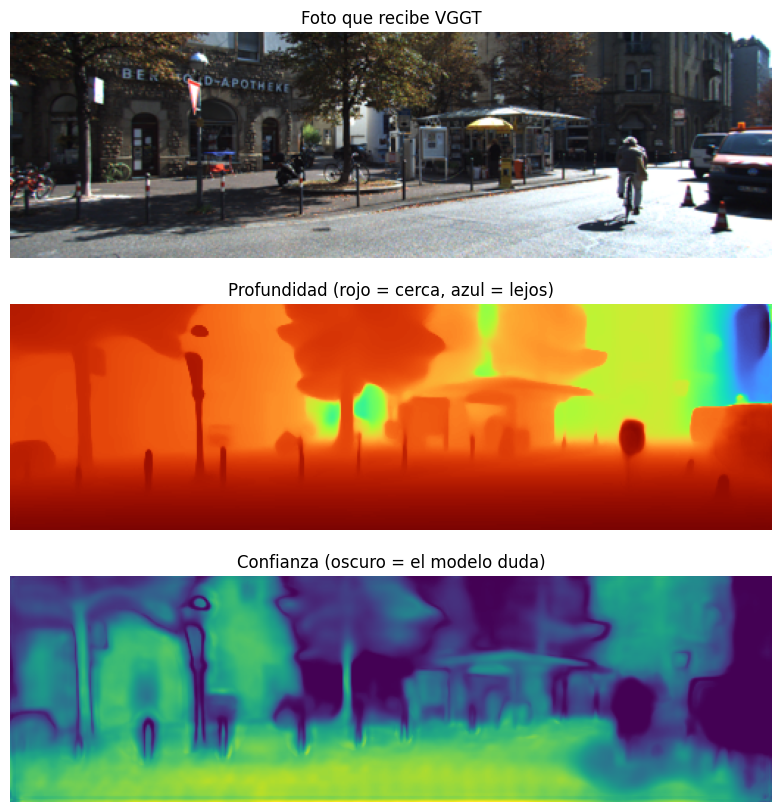

Profundidad mínima: 0.13 | máxima: 1.28
Ojo: estos números NO son metros, son unidades propias de VGGT


In [ ]:
# Miramos una foto del medio del recorrido
i = len(CUADROS) // 2

fig, ax = plt.subplots(3, 1, figsize=(16, 10))
ax[0].imshow(colores[i]); ax[0].set_title("Foto que recibe VGGT")
ax[1].imshow(profundidad[i], cmap="turbo_r"); ax[1].set_title("Profundidad (rojo = cerca, azul = lejos)")
ax[2].imshow(confianza[i], cmap="viridis"); ax[2].set_title("Confianza (oscuro = el modelo duda)")
for a in ax:
    a.axis("off")
plt.show()

print(f"Profundidad mínima: {profundidad[i].min():.2f} | máxima: {profundidad[i].max():.2f}")
print("Ojo: estos números NO son metros, son unidades propias de VGGT")

El modelo duda en el **cielo** (no tiene distancia) y en los **bordes** de los objetos.

Con una sola cámara **no se puede saber la escala**: una foto de un auto real a 10 m y la de un auto de juguete a 10 cm se ven iguales. Por eso VGGT entrega todo en unidades propias.

## **4.- ¿Por dónde anduvo el auto?**

VGGT nos da, para cada foto, la matriz $[R \mid t]$ que lleva un punto del mundo al sistema de la cámara. El mundo es la **primera foto**.

La pose tiene dos partes:

* dónde está la cámara: su posición, el centro C
* hacia dónde mira: su orientación, la rotación R

$$C = -R^T \, t$$

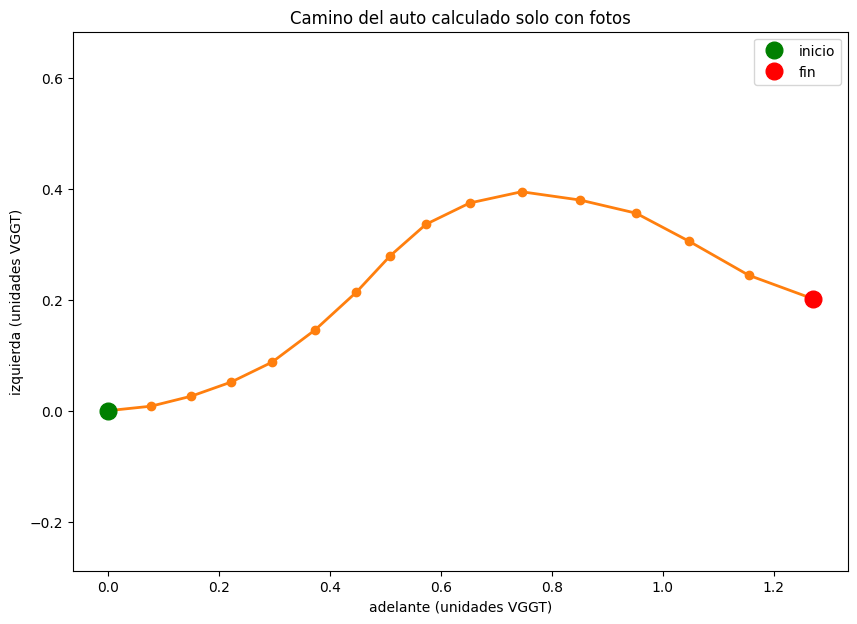

In [ ]:
# Calculamos el centro de la cámara en cada foto
centros = np.array([-E[:, :3].T @ E[:, 3] for E in extr])

# La cámara usa x derecha, y abajo, z adelante. Para ver desde arriba usamos adelante (z) e izquierda (-x)
camino = np.stack([centros[:, 2], -centros[:, 0]], axis=1)

plt.figure(figsize=(10, 7))
plt.plot(camino[:, 0], camino[:, 1], "tab:orange", lw=2, marker="o")
plt.plot(camino[0, 0], camino[0, 1], "go", ms=12, label="inicio")
plt.plot(camino[-1, 0], camino[-1, 1], "ro", ms=12, label="fin")
plt.axis("equal"); plt.legend()
plt.xlabel("adelante (unidades VGGT)"); plt.ylabel("izquierda (unidades VGGT)")
plt.title("Camino del auto calculado solo con fotos")
plt.show()

La **forma** del camino es correcta, pero no sabemos cuántos metros son.

**Truco:** sabemos que la cámara está montada a **1.65 m del piso**. Si medimos en la primera foto a qué "altura" ve VGGT la calle justo delante del auto, podemos convertir sus unidades a metros.

In [ ]:
# En la primera foto, tomamos los píxeles de abajo al centro: ahí casi siempre hay calle
calle = puntos[0, H - 25:H - 5, W // 3: 2 * W // 3].reshape(-1, 3)

# El eje y de la cámara apunta hacia abajo, así que su valor es la altura de la cámara sobre la calle
altura_vggt = np.median(calle[:, 1])
escala = 1.65 / altura_vggt
print(f"La calle está {altura_vggt:.3f} unidades por debajo de la cámara")
print(f"Entonces 1 unidad de VGGT = {escala:.1f} m")

# el camino en metros
camino_m = camino * escala
pasos = np.sqrt(np.sum(np.diff(camino_m, axis=0)**2, axis=1))
segundos = (CUADROS[-1] - CUADROS[0]) / 10
print(f"El auto recorrió {pasos.sum():.1f} m en {segundos:.0f} s")
print(f"Velocidad media: {pasos.sum() / segundos * 3.6:.0f} km/h")

La calle está 0.035 unidades por debajo de la cámara
Entonces 1 unidad de VGGT = 47.2 m
El auto recorrió 67.6 m en 15 s
Velocidad media: 16 km/h


## **5.- La escena en 3D**

VGGT también nos da un punto 3D para cada píxel de cada foto. Los juntamos todos, ya en metros, con el color de la foto.

In [ ]:
# Juntamos los puntos de todas las fotos
Q = puntos.reshape(-1, 3) * escala
C = colores.reshape(-1, 3)
c = conf_puntos.reshape(-1)

# Nos quedamos con la mitad de puntos más confiables y tomamos 60 000 al azar para que el gráfico no sea lento
buenos = np.flatnonzero(c > np.percentile(c, 50))
idx = np.random.choice(buenos, 60000, replace=False)
Q, C = Q[idx], (C[idx] * 255).astype(int)

# Ordenamos los ejes como en la clase que veremos de LiDAR: adelante, izquierda, arriba
fig = go.Figure()
fig.add_trace(go.Scatter3d(x=Q[:, 2], y=-Q[:, 0], z=-Q[:, 1], mode="markers", name="puntos",
                           marker=dict(size=1.2, color=[f"rgb({r},{g},{b})" for r, g, b in C])))
fig.add_trace(go.Scatter3d(x=camino_m[:, 0], y=camino_m[:, 1], z=np.zeros(len(camino_m)),
                           mode="lines+markers", name="cámara", line=dict(color="red", width=5)))
fig.update_layout(height=600, title="Escena reconstruida por VGGT solo con fotos (en metros)",
                  scene=dict(aspectmode="data"))
fig.show()

Podemos girar la escena con el mouse: se ven la calle, las paredes, los autos estacionados y el camino de la cámara en rojo. Los autos que se movieron suelen salir borrosos o repetidos, porque el modelo supone que la escena está quieta.